# A/B Test Analysis: One-Page Checkout Redesign

**Business context:** The product team redesigned the checkout flow (old: 3 steps, new: single page). 64,000 users were randomly
split 50/50 over 14 days. *Should we roll it out?*

## Experiment design
| Item | Choice |
|---|---|
| Hypothesis | H0: conversion rate is the same. H1: the new checkout changes conversion rate |
| Unit of randomisation | User |
| **Primary metric** | Conversion rate (user placed an order) |
| Secondary metric | Revenue per user (RPU) |
| Guardrail | Average order value (AOV) of converters must not drop |
| Significance level | α = 0.05 (two-sided), target power 80% |

**Analysis plan:** validate data → check randomisation (SRM) → primary test → secondary/guardrail → segment effects (with multiple-testing correction) → novelty check → business impact → decision.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests
from IPython.display import Markdown, display
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
IMG = "../images/"; rng = np.random.default_rng(0)
df = pd.read_csv("../data/ab_test_checkout.csv", parse_dates=["date"])
df.head()

,user_id,date,group,device,user_type,traffic_source,converted,revenue
0,100008,2025-09-01,control,desktop,new,paid,0,0.0
1,100014,2025-09-01,treatment,mobile,new,organic,0,0.0
2,100065,2025-09-01,control,desktop,returning,direct,0,0.0
3,100082,2025-09-01,control,mobile,new,direct,0,0.0
4,100096,2025-09-01,control,mobile,returning,paid,0,0.0


## 1. Data validation

In [2]:
print("Rows:", len(df), "| unique users:", df.user_id.nunique(), "| duplicates:", df.user_id.duplicated().sum())
print("Missing values:", int(df.isna().sum().sum()), "| date range:", df.date.min().date(), "->", df.date.max().date())
print("Conversion is binary:", set(df.converted.unique()), "| revenue>0 only when converted:", bool(((df.revenue > 0) == (df.converted == 1)).all()))
df.groupby("group").agg(users=("user_id", "size"), conversions=("converted", "sum"))

Rows: 64000 | unique users: 64000 | duplicates: 0
Missing values: 0 | date range: 2025-09-01 -> 2025-09-14
Conversion is binary: {np.int64(0), np.int64(1)} | revenue>0 only when converted: True


,users,conversions
group,,
control,31887,3282
treatment,32113,3710


## 2. Is the randomisation trustworthy?
**Sample Ratio Mismatch (SRM):** if the split deviates from 50/50 more than chance allows, the experiment is broken and results can't be trusted.
We also check that device / user type / traffic source are balanced across groups.

In [3]:
counts = df.group.value_counts()
chi2, p_srm = stats.chisquare(counts.loc[["control", "treatment"]], f_exp=[len(df)/2]*2)
print(f"SRM chi-square test: control={counts['control']:,}, treatment={counts['treatment']:,}, p={p_srm:.3f} -> {'PASS (no SRM)' if p_srm > 0.001 else 'FAIL - investigate!'}")
bal = []
for col in ["device", "user_type", "traffic_source"]:
    ct = pd.crosstab(df[col], df.group); p = stats.chi2_contingency(ct)[1]
    bal.append((col, round(p, 3), "balanced" if p > 0.05 else "IMBALANCED"))
pd.DataFrame(bal, columns=["covariate", "chi2 p-value", "verdict"])

SRM chi-square test: control=31,887, treatment=32,113, p=0.372 -> PASS (no SRM)


,covariate,chi2 p-value,verdict
0,device,0.061,balanced
1,user_type,0.780,balanced
2,traffic_source,0.768,balanced


## 3. Was the test big enough? (power)
With a baseline of ~10% conversion, how many users per group are needed to detect a **+1 percentage point** lift?

In [4]:
base = df[df.group == "control"].converted.mean()
es = proportion_effectsize(base + 0.01, base)
n_req = NormalIndPower().solve_power(es, power=0.8, alpha=0.05, ratio=1)
n_have = df.group.value_counts().min()
power_have = NormalIndPower().solve_power(es, nobs1=n_have, alpha=0.05, ratio=1)
print(f"Baseline conversion: {base:.2%}")
print(f"Users needed per group to detect +1pp (80% power): {n_req:,.0f}")
print(f"Users we have per group: {n_have:,}  ->  power to detect +1pp = {power_have:.0%}")

Baseline conversion: 10.29%
Users needed per group to detect +1pp (80% power): 15,106
Users we have per group: 31,887  ->  power to detect +1pp = 98%


## 4. Primary metric: conversion rate

Control   : 10.29%  (n=31,887)
Treatment : 11.55%  (n=32,113)
Absolute lift: +1.26 pp   95% CI [+0.78, +1.74] pp
Relative lift: +12.2%   two-proportion z-test p-value = 3.2e-07


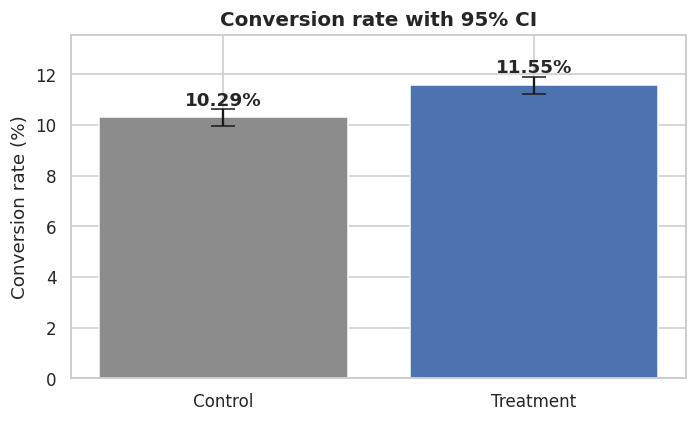

In [5]:
def ab(d):
    c, t = d[d.group == "control"], d[d.group == "treatment"]
    nc, nt, xc, xt = len(c), len(t), c.converted.sum(), t.converted.sum()
    z, p = proportions_ztest([xt, xc], [nt, nc])
    lo, hi = confint_proportions_2indep(xt, nt, xc, nc, method="wald")
    return dict(n_control=nc, n_treatment=nt, cr_control=xc/nc, cr_treatment=xt/nt, lift_pp=(xt/nt - xc/nc)*100,
                ci_low_pp=lo*100, ci_high_pp=hi*100, rel_lift=(xt/nt)/(xc/nc) - 1, p_value=p)
res = ab(df)
print(f"Control   : {res['cr_control']:.2%}  (n={res['n_control']:,})")
print(f"Treatment : {res['cr_treatment']:.2%}  (n={res['n_treatment']:,})")
print(f"Absolute lift: {res['lift_pp']:+.2f} pp   95% CI [{res['ci_low_pp']:+.2f}, {res['ci_high_pp']:+.2f}] pp")
print(f"Relative lift: {res['rel_lift']:+.1%}   two-proportion z-test p-value = {res['p_value']:.2g}")

fig, ax = plt.subplots(figsize=(6.5, 4))
rates = [res["cr_control"]*100, res["cr_treatment"]*100]
err = [1.96*np.sqrt(r/100*(1-r/100)/n)*100 for r, n in zip(rates, [res["n_control"], res["n_treatment"]])]
ax.bar(["Control", "Treatment"], rates, yerr=err, capsize=8, color=["#8c8c8c", "#4c72b0"])
for i, r in enumerate(rates): ax.text(i, r + err[i] + .15, f"{r:.2f}%", ha="center", fontweight="bold")
ax.set_ylabel("Conversion rate (%)"); ax.set_ylim(0, max(rates) + 2); ax.set_title("Conversion rate with 95% CI")
plt.tight_layout(); plt.savefig(IMG + "01_conversion_ci.png"); plt.show()

## 5. Secondary metric and guardrail
* **Revenue per user (RPU)** - includes non-buyers (zeros), so it captures conversion x order value. Revenue is heavy-tailed, so we use a **bootstrap** CI.
* **AOV guardrail** - the redesign must not lower basket size. Tested with Mann-Whitney (robust to skew).

RPU  control ₹200.5 | treatment ₹225.7 | diff ₹+25.2  bootstrap 95% CI [₹+13.5, ₹+37.5]
AOV  control ₹1,948 | treatment ₹1,954 | Mann-Whitney p = 0.77  -> guardrail PASSED (no drop)


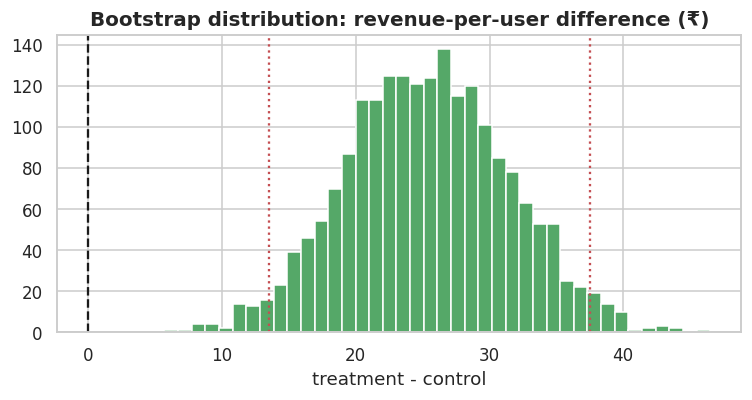

In [6]:
c_rev = df[df.group == "control"].revenue.values; t_rev = df[df.group == "treatment"].revenue.values
obs_diff = t_rev.mean() - c_rev.mean()
boot = np.array([rng.choice(t_rev, len(t_rev)).mean() - rng.choice(c_rev, len(c_rev)).mean() for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"RPU  control ₹{c_rev.mean():.1f} | treatment ₹{t_rev.mean():.1f} | diff ₹{obs_diff:+.1f}  bootstrap 95% CI [₹{lo:+.1f}, ₹{hi:+.1f}]")

buyers = df[df.converted == 1]; ca = buyers[buyers.group == "control"].revenue; ta = buyers[buyers.group == "treatment"].revenue
u, p_aov = stats.mannwhitneyu(ta, ca)
print(f"AOV  control ₹{ca.mean():,.0f} | treatment ₹{ta.mean():,.0f} | Mann-Whitney p = {p_aov:.2f}  -> guardrail {'PASSED (no drop)' if (p_aov > .05 or ta.mean() >= ca.mean()) else 'FAILED'}")

plt.figure(figsize=(7, 3.8)); plt.hist(boot, bins=40, color="#55a868", edgecolor="white"); plt.axvline(0, c="k", ls="--"); plt.axvline(lo, c="r", ls=":"); plt.axvline(hi, c="r", ls=":")
plt.title("Bootstrap distribution: revenue-per-user difference (₹)"); plt.xlabel("treatment - control"); plt.tight_layout(); plt.savefig(IMG + "02_bootstrap_rpu.png"); plt.show()

## 6. Who benefits? Segment analysis
Averages can hide the story. We test the lift inside each segment, and because we run many tests we correct p-values with **Holm's method**
(otherwise some segment will look "significant" by luck).

,segment,n_control,cr_control,cr_treatment,lift_pp,ci_low_pp,ci_high_pp,p_value,p_holm,significant
0,device = desktop,11630,12.36%,12.61%,+0.25,-0.60,+1.11,0.559,0.559,False
1,device = mobile,20257,9.11%,10.96%,+1.86,+1.27,+2.44,4.25e-10,3.4e-09,True
2,user_type = new,18478,8.52%,9.72%,+1.20,+0.61,+1.79,5.95e-05,0.000417,True
3,user_type = returning,13409,12.73%,14.09%,+1.35,+0.54,+2.17,0.00112,0.0067,True
4,traffic_source = direct,6439,11.06%,12.22%,+1.16,+0.06,+2.27,0.0392,0.103,False
5,traffic_source = email,4789,13.32%,14.82%,+1.50,+0.11,+2.88,0.0344,0.103,False
6,traffic_source = organic,11175,9.97%,11.30%,+1.33,+0.52,+2.14,0.00128,0.0067,True
7,traffic_source = paid,9484,8.63%,9.74%,+1.11,+0.30,+1.93,0.00766,0.0306,True


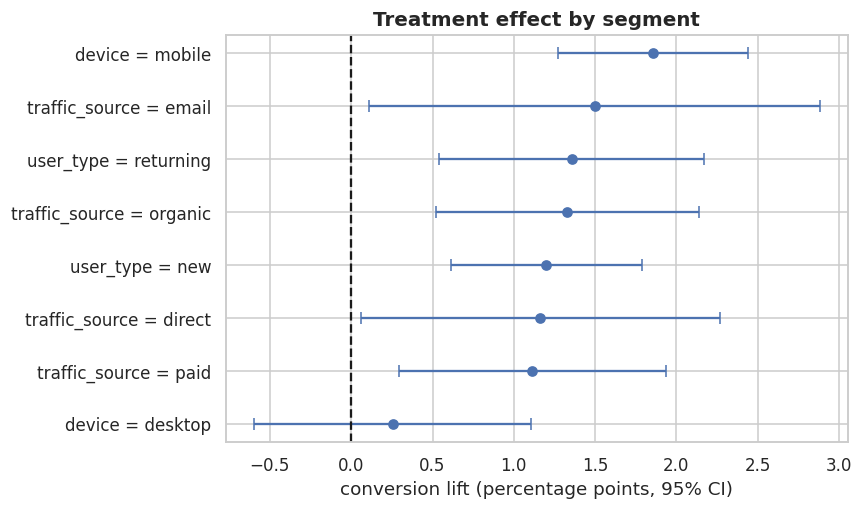

In [7]:
rows = []
for col in ["device", "user_type", "traffic_source"]:
    for val, d in df.groupby(col):
        r = ab(d); r.update(segment=f"{col} = {val}"); rows.append(r)
seg = pd.DataFrame(rows)
seg["p_holm"] = multipletests(seg.p_value, method="holm")[1]
seg["significant"] = seg.p_holm < 0.05
show = seg[["segment", "n_control", "cr_control", "cr_treatment", "lift_pp", "ci_low_pp", "ci_high_pp", "p_value", "p_holm", "significant"]]
display(show.style.format({"cr_control": "{:.2%}", "cr_treatment": "{:.2%}", "lift_pp": "{:+.2f}", "ci_low_pp": "{:+.2f}", "ci_high_pp": "{:+.2f}", "p_value": "{:.3g}", "p_holm": "{:.3g}"}))

s = seg.sort_values("lift_pp"); y = np.arange(len(s))
plt.figure(figsize=(8, 4.8))
plt.errorbar(s.lift_pp, y, xerr=[s.lift_pp - s.ci_low_pp, s.ci_high_pp - s.lift_pp], fmt="o", color="#4c72b0", capsize=4)
plt.axvline(0, c="k", ls="--"); plt.yticks(y, s.segment); plt.xlabel("conversion lift (percentage points, 95% CI)"); plt.title("Treatment effect by segment")
plt.tight_layout(); plt.savefig(IMG + "03_segment_forest.png"); plt.show()

### Is the mobile-vs-desktop difference real? - interaction test
A logistic regression with a `treatment x mobile` interaction asks directly whether the treatment effect differs by device.

In [8]:
df["treat"] = (df.group == "treatment").astype(int); df["mobile"] = (df.device == "mobile").astype(int)
m = smf.logit("converted ~ treat * mobile", data=df).fit(disp=0)
print(m.summary().tables[1])
p_int = m.pvalues["treat:mobile"]
print(f"\nInteraction p-value = {p_int:.1g} -> the effect {'DIFFERS' if p_int < .05 else 'does not clearly differ'} between mobile and desktop")
print(f"Odds ratio (treatment, desktop): {np.exp(m.params['treat']):.2f} | extra odds ratio on mobile: {np.exp(m.params['treat:mobile']):.2f}")

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -1.9591      0.028    -69.527      0.000      -2.014      -1.904
treat            0.0232      0.040      0.584      0.559      -0.055       0.101
mobile          -0.3414      0.037     -9.155      0.000      -0.414      -0.268
treat:mobile     0.1829      0.052      3.535      0.000       0.082       0.284

Interaction p-value = 0.0004 -> the effect DIFFERS between mobile and desktop
Odds ratio (treatment, desktop): 1.02 | extra odds ratio on mobile: 1.20


## 7. Novelty effect check
New designs often get an initial bump that fades. Is the lift stable over time?

,week,device,lift_pp,ci_low_pp,ci_high_pp,p_value
0,Week 1,desktop,-0.485,-1.698,0.728,0.433
1,Week 1,mobile,1.997,1.164,2.830,0.000
2,Week 2,desktop,0.977,-0.221,2.176,0.110
3,Week 2,mobile,1.721,0.908,2.534,0.000


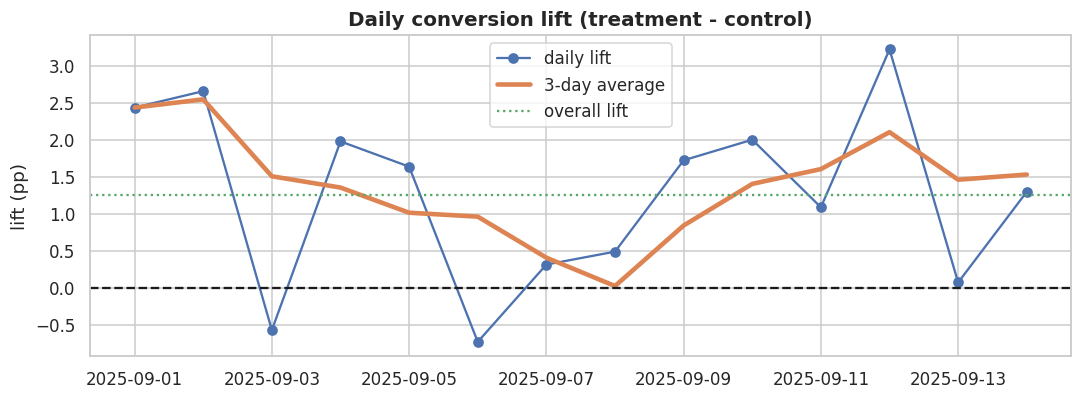

Mobile lift: Week 1 +2.00 pp -> Week 2 +1.72 pp (still positive after novelty fades)


In [9]:
df["week"] = np.where((df.date - df.date.min()).dt.days < 7, "Week 1", "Week 2")
wk = pd.DataFrame([dict(week=w, device=dv, **{k: v for k, v in ab(d).items() if k in ("lift_pp", "ci_low_pp", "ci_high_pp", "p_value")})
                   for (w, dv), d in df.groupby(["week", "device"])])
display(wk.round(3))
daily = df.groupby(["date", "group"]).converted.mean().unstack(); daily["lift_pp"] = (daily.treatment - daily.control) * 100
plt.figure(figsize=(10, 3.8)); plt.plot(daily.index, daily.lift_pp, marker="o", label="daily lift"); plt.plot(daily.index, daily.lift_pp.rolling(3, min_periods=1).mean(), lw=3, label="3-day average")
plt.axhline(0, c="k", ls="--"); plt.axhline(res["lift_pp"], c="g", ls=":", label="overall lift"); plt.legend(); plt.ylabel("lift (pp)"); plt.title("Daily conversion lift (treatment - control)")
plt.tight_layout(); plt.savefig(IMG + "04_daily_lift.png"); plt.show()
mob = wk[wk.device == "mobile"].set_index("week").lift_pp
print(f"Mobile lift: Week 1 {mob['Week 1']:+.2f} pp -> Week 2 {mob['Week 2']:+.2f} pp (still positive after novelty fades)" if mob['Week 2'] > 0 else "Mobile lift disappears in week 2 - novelty effect!")

## 8. Business impact

In [10]:
mob_r, desk_r = seg.set_index("segment").loc["device = mobile"], seg.set_index("segment").loc["device = desktop"]
avg_order = buyers.revenue.mean()
print(f"Per 100,000 visitors, overall rollout -> ~{res['lift_pp']*1000:,.0f} extra orders  (95% CI {res['ci_low_pp']*1000:,.0f} to {res['ci_high_pp']*1000:,.0f})")
print(f"Revenue per 100,000 visitors: ≈ ₹{obs_diff*1e5/1e5:,.1f} L extra  (bootstrap 95% CI ₹{lo*1e5/1e5:,.1f} L to ₹{hi*1e5/1e5:,.1f} L)")
print(f"Mobile only: {mob_r.lift_pp:+.2f} pp (CI {mob_r.ci_low_pp:+.2f} to {mob_r.ci_high_pp:+.2f}), p_holm={mob_r.p_holm:.3g}")
print(f"Desktop only: {desk_r.lift_pp:+.2f} pp (CI {desk_r.ci_low_pp:+.2f} to {desk_r.ci_high_pp:+.2f}), p_holm={desk_r.p_holm:.3g}")

Per 100,000 visitors, overall rollout -> ~1,260 extra orders  (95% CI 777 to 1,744)
Revenue per 100,000 visitors: ≈ ₹25.2 L extra  (bootstrap 95% CI ₹13.5 L to ₹37.5 L)
Mobile only: +1.86 pp (CI +1.27 to +2.44), p_holm=3.4e-09
Desktop only: +0.25 pp (CI -0.60 to +1.11), p_holm=0.559


## 9. Recommendation

In [11]:
sig_mobile = mob_r.p_holm < .05; sig_desk = desk_r.p_holm < .05
display(Markdown(f'''
**Decision: ship the new checkout** - starting with mobile.

1. **Primary metric:** conversion rose from {res['cr_control']:.2%} to {res['cr_treatment']:.2%} ({res['lift_pp']:+.2f} pp, {res['rel_lift']:+.0%} relative, 95% CI {res['ci_low_pp']:+.2f} to {res['ci_high_pp']:+.2f} pp, p = {res['p_value']:.1g}).
2. **Guardrail:** average order value did not drop (₹{ta.mean():,.0f} vs ₹{ca.mean():,.0f}); revenue per user rose ₹{obs_diff:.0f}.
3. **Where the gain comes from:** mobile {mob_r.lift_pp:+.2f} pp ({'significant' if sig_mobile else 'not significant'} after Holm correction) vs desktop {desk_r.lift_pp:+.2f} pp ({'significant' if sig_desk else 'not significant'}). Interaction test p = {p_int:.1g}.
4. **Trust checks passed:** no sample-ratio mismatch (p = {p_srm:.2f}), covariates balanced, adequate power ({power_have:.0%} for a +1 pp effect).
5. **Risks / next steps:** roll out to mobile at 100% and monitor for 2 more weeks; keep desktop on a holdout (no proven benefit); investigate why desktop did not respond (the old flow may already be efficient on large screens).

*Caveats:* 14-day test, synthetic data, no long-term retention measured; segment results are exploratory and should be confirmed with a follow-up test.
'''))


**Decision: ship the new checkout** - starting with mobile.

1. **Primary metric:** conversion rose from 10.29% to 11.55% (+1.26 pp, +12% relative, 95% CI +0.78 to +1.74 pp, p = 3e-07).
2. **Guardrail:** average order value did not drop (₹1,954 vs ₹1,948); revenue per user rose ₹25.
3. **Where the gain comes from:** mobile +1.86 pp (significant after Holm correction) vs desktop +0.25 pp (not significant). Interaction test p = 0.0004.
4. **Trust checks passed:** no sample-ratio mismatch (p = 0.37), covariates balanced, adequate power (98% for a +1 pp effect).
5. **Risks / next steps:** roll out to mobile at 100% and monitor for 2 more weeks; keep desktop on a holdout (no proven benefit); investigate why desktop did not respond (the old flow may already be efficient on large screens).

*Caveats:* 14-day test, synthetic data, no long-term retention measured; segment results are exploratory and should be confirmed with a follow-up test.
